In [ ]:
import pandas as pd
import matplotlib as plt
import plotly.graph_objects as go # Importación de plotly.graph_objects como go

# Leer los datos del archivo CSV
car_data = pd.read_csv('vehicles_us.csv')

car_data


,price,model_year,model,condition,cylinders,fuel,odometer,transmission,type,paint_color,is_4wd,date_posted,days_listed
0,9400,2011.0,bmw x5,good,6.0,gas,145000.0,automatic,SUV,NaN,1.0,2018-06-23,19
1,25500,NaN,ford f-150,good,6.0,gas,88705.0,automatic,pickup,white,1.0,2018-10-19,50
2,5500,2013.0,hyundai sonata,like new,4.0,gas,110000.0,automatic,sedan,red,NaN,2019-02-07,79
3,1500,2003.0,ford f-150,fair,8.0,gas,NaN,automatic,pickup,NaN,NaN,2019-03-22,9
4,14900,2017.0,chrysler 200,excellent,4.0,gas,80903.0,automatic,sedan,black,NaN,2019-04-02,28
...,...,...,...,...,...,...,...,...,...,...,...,...,...
51520,9249,2013.0,nissan maxima,like new,6.0,gas,88136.0,automatic,sedan,black,NaN,2018-10-03,37
51521,2700,2002.0,honda civic,salvage,4.0,gas,181500.0,automatic,sedan,white,NaN,2018-11-14,22
51522,3950,2009.0,hyundai sonata,excellent,4.0,gas,128000.0,automatic,sedan,blue,NaN,2018-11-15,32
51523,7455,2013.0,toyota corolla,good,4.0,gas,139573.0,automatic,sedan,black,NaN,2018-07-02,71


## Tipos de dato en cada columna 

In [3]:
car_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51525 entries, 0 to 51524
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   price         51525 non-null  int64  
 1   model_year    47906 non-null  float64
 2   model         51525 non-null  object 
 3   condition     51525 non-null  object 
 4   cylinders     46265 non-null  float64
 5   fuel          51525 non-null  object 
 6   odometer      43633 non-null  float64
 7   transmission  51525 non-null  object 
 8   type          51525 non-null  object 
 9   paint_color   42258 non-null  object 
 10  is_4wd        25572 non-null  float64
 11  date_posted   51525 non-null  object 
 12  days_listed   51525 non-null  int64  
dtypes: float64(4), int64(2), object(7)
memory usage: 5.1+ MB


## Valores faltantes o registros duplicados (si existen)

In [54]:
model_year_isna = car_data['model_year'].isna().sum()
cylinders_isna = car_data['cylinders'].isna().sum()
odometer_isna = car_data['odometer'].isna().sum()
paint_color_isna = car_data['paint_color'].isna().sum()
is_4wd_isna = car_data['is_4wd'].isna().sum()
print(f"Número de valores ausentes en la columna Año de modelo: {model_year_isna},         93/100 % ")
print(f"Número de valores ausentes en la columna Número de cilindros: {cylinders_isna},   89.8/100 % ")
print(f"Número de valores ausentes en la columna Odómetro: {odometer_isna}               84.7/100% ")
print(f"Número de valores ausentes en la columna Color de pintura: {paint_color_isna}       82/100 %")
print(f"Número de valores ausentes en la columna Tracción (4wd): {is_4wd_isna}        49.6/100 %")

Número de valores ausentes en la columna Año de modelo: 3619,         93/100 % 
Número de valores ausentes en la columna Número de cilindros: 5260,   89.8/100 % 
Número de valores ausentes en la columna Odómetro: 7892               84.7/100% 
Número de valores ausentes en la columna Color de pintura: 9267       82/100 %
Número de valores ausentes en la columna Tracción (4wd): 25953        49.6/100 %


## Estadísticas descriptivas relevantes.

In [5]:
w = car_data['price'].describe()
print(w)
mean_price = car_data['price'].mean()
median_price = car_data['price'].median()
print()
print(f"Precio promedio: ${mean_price}")
print(f"Mediana de precios: ${median_price}")

count     51525.000000
mean      12132.464920
std       10040.803015
min           1.000000
25%        5000.000000
50%        9000.000000
75%       16839.000000
max      375000.000000
Name: price, dtype: float64

Precio promedio: $12132.464919941776
Mediana de precios: $9000.0


Existen valores de precios muy altos que arrastran hacia arriba el valor promedio de los precios por lo que el 50% de los precios se ubica debajo de 9,000 y el 50% restante por encima de ese valor. Sin embargo, existen varios anuncios con valor de 1 (como se observa en el valor mínimo), esto significa que son valores representativos y no valores reales 

<Axes: title={'center': 'Precio vs Tipo de vehículo'}, xlabel='Tipo de vehículo', ylabel='Precio [USD]'>

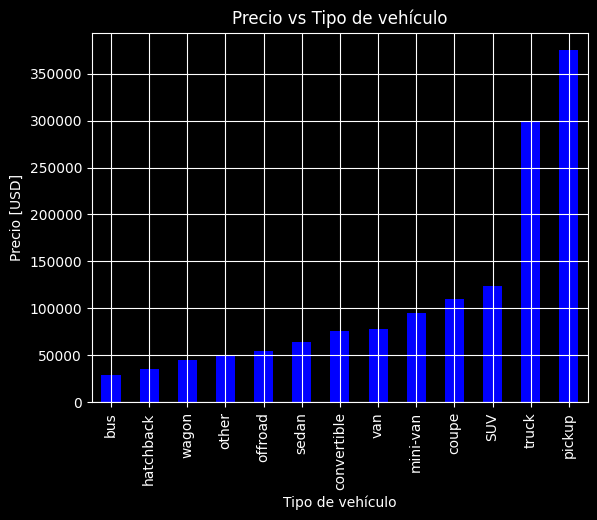

In [44]:
sw = car_data.groupby('type')['price'].max()
sw = sw.reset_index().sort_values(by='price',ascending=True)
plt.style.use('dark_background')
sw.plot(kind='bar',
        x='type',
        y='price',
        grid=True,
        color='blue',
        title='Precio vs Tipo de vehículo',
        legend=False,
        ylabel='Precio [USD]',
        xlabel='Tipo de vehículo')

count     43633.000000
mean     115553.461738
std       65094.611341
min           0.000000
25%       70000.000000
50%      113000.000000
75%      155000.000000
max      990000.000000
Name: odometer, dtype: float64

Millaje promedio:             115553.4617376756
Mediana de odómetro [millas]: 113000.0


<Axes: title={'center': 'Odómetro vs Tipo de vehiculo'}, xlabel='Tipo de vehículo', ylabel='Odómetro [millas]'>

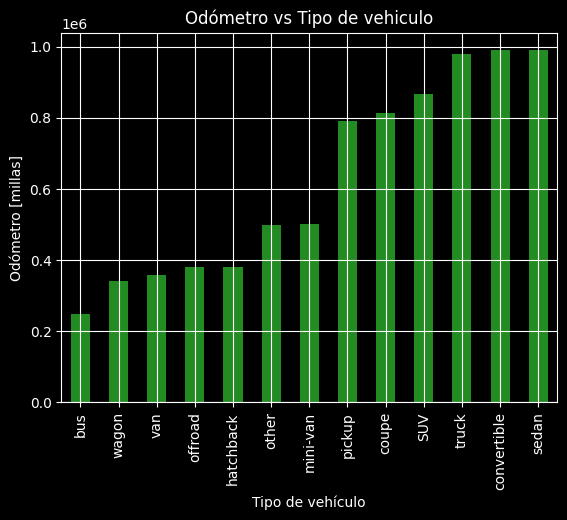

In [43]:
z = car_data['odometer'].describe()
print(z)
odometer_mean = car_data['odometer'].mean()
odometer_median = car_data['odometer'].median()
print()
print(f"Millaje promedio:             {odometer_mean}")
print(f"Mediana de odómetro [millas]: {odometer_median}")

sq = car_data.groupby('type')['odometer'].max()
sq = sq.reset_index().sort_values(by='odometer',ascending=True)
sq.plot(kind='bar',
        x='type',
        y='odometer',
        grid=True,
        color='forestgreen',
        xlabel='Tipo de vehículo',
        ylabel='Odómetro [millas]',
        title='Odómetro vs Tipo de vehiculo',
        legend=False)

<Axes: title={'center': 'Precio mediano por año del modelo'}, xlabel='Año del modelo', ylabel='Precio mediano (USD)'>

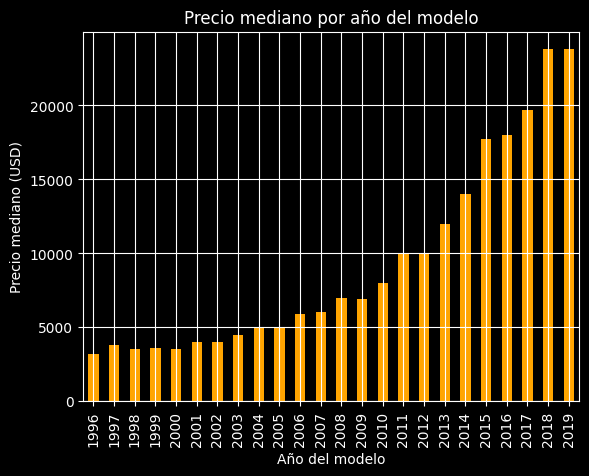

In [52]:
hk = car_data[car_data['model_year'] > 1995].groupby('model_year')['price'].median()
hk = hk.reset_index()
hk['model_year'] = hk['model_year'].astype(int)

plt.style.use('dark_background')
hk.plot(kind='bar', 
        x='model_year', 
        y='price', 
        grid=True, 
        color='orange',
        title='Precio mediano por año del modelo',
        legend=False,
        ylabel='Precio mediano (USD)', 
        xlabel='Año del modelo')


## Hallazgos o conclusiones que justifiquen las decisiones tomadas posteriormente en el desarrollo de la aplicación.

1. Pick up & Truck son los modelos que dominan el mercado ocupando el primer y segundo lugar con mayor precio en los anuncios publicados

2. Existen diversas columnas con valores ausentes en "tipo de tracción (is_4wd)" con 49.6%  o "color de la pintura" con 82% de filas con valor. 
Para realizar una compra no son datos estrictamente necesarios, sin embargo, aunque la columna "precio" no cuente con valores ausentes, cuenta con valores espurios con filas que tienen el valor de "1"; un valor simbólico que no representa el valor real y que puede afectar tanto la interpretación como el análisis

3. Existe una mayor densidad de vehículos con modelos recientes (2015-2019) mientras que debajo de ese umbral (70%) la mediana de precios es inferior a los 15,000 USD

4. Los modelos con mayor millaje son los tipo sedán, convertible y tipo truck (+ 800,000 mi) mientras que los modelos con menor kilometraje son el bus, tipo wagon y van ( -400,000 mi) 


count     43633.000000
mean     115553.461738
std       65094.611341
min           0.000000
25%       70000.000000
50%      113000.000000
75%      155000.000000
max      990000.000000
Name: odometer, dtype: float64

Millaje promedio:             115553.4617376756
Mediana de odómetro [millas]: 113000.0


<Axes: title={'center': 'Odómetro vs Tipo de vehiculo'}, xlabel='Tipo de vehículo', ylabel='Odómetro [millas]'>

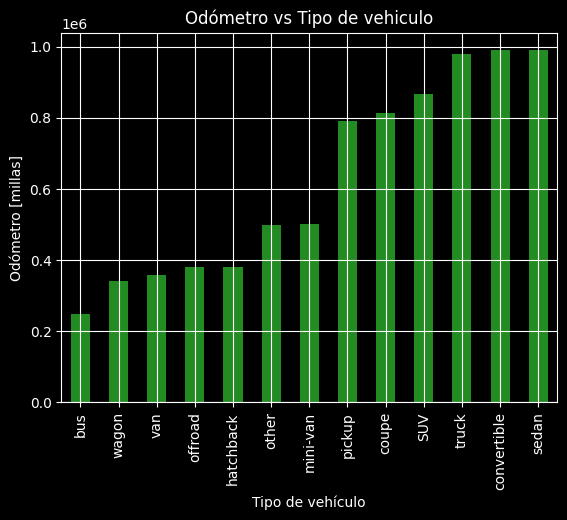

In [ ]:
z = car_data['odometer'].describe()
print(z)
odometer_mean = car_data['odometer'].mean()
odometer_median = car_data['odometer'].median()
print()
print(f"Millaje promedio:             {odometer_mean}")
print(f"Mediana de odómetro [millas]: {odometer_median}")

sq = car_data.groupby('type')['odometer'].max()
sq = sq.reset_index().sort_values(by='odometer',ascending=True)
sq.plot(kind='bar',
        x='type',
        y='odometer',
        grid=True,
        color='forestgreen',
        xlabel='Tipo de vehículo',
        ylabel='Odómetro [millas]',
        title='Odómetro vs Tipo de vehiculo',
        legend=False)